# 05 Random forest on the G0–G3 feature sets

This notebook tunes and validates random forest on the four cumulative feature sets built in
`02_feature_engineering.ipynb`: G0 raw columns (197) → G1 + row-level features (224) → G2 + card and device
history (234) → G3 + customer history (252). All six model notebooks (04 to 09) follow the same steps and call the
same code in `src/`, so their results can be compared directly in `10_model_comparison.ipynb`.

- **Data:** `data/processed/features_v2.parquet` (build it with `02_feature_engineering.ipynb`). `src.feature_sets`
  drops the test block before anything else sees it, so this notebook never touches it.
- **Splits:** `src/split.py`. Training block = the first 472,432 rows by time; validation = the next 59,054.
- **Every fit** appends one row to `results/log.csv`. Rerunning the notebook skips anything already logged, so it
  can be stopped and restarted. Validation scores are saved to `results/preds/` (not in git) for the comparison
  notebook and a possible ensemble.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Import the model library before anything else: on macOS some model libraries clash with PyTorch's
# threading library if PyTorch is loaded first (see tests/conftest.py).
from src.models import rf as model

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sklearn.metrics import precision_recall_curve

from src import data, experiment, feature_sets as fs, importance, segments
from src.metrics import top_rows

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

## 1. Settings

- `FEATURE_SETS`: the sets to validate on.
- `TUNE_ON`: `"G3"` tunes once, on the full set, and validates those settings on every set, so the sets are
  compared with the model held fixed. `None` tunes every set separately (four times the tuning cost).
- `GRID`: the settings tried during tuning, defined in the model's file in `src/models/` (logistic regression 11,
  random forest 12, MLP 16, LightGBM, XGBoost and CatBoost 20 each, so every model gets a comparable search). For a quick trial, use e.g. `model.GRID[:2]`, but log such a trial to a
  separate file (`LOG_PATH`) so it doesn't mix with the real runs.
- `SEEDS`: the validation seeds (0, 1, 2 for the group's results).
- `SAVE_OOF`: also save the time-CV fold scores of the chosen settings (4 extra fits per set), needed to train a
  stacking model later.
- `IMPORTANCE_SET`, `IMPORTANCE_ROWS`: the feature set and the number of validation rows used for feature importance
  (section 6). More rows give steadier numbers but take longer.

In [2]:
FEATURE_SETS = ["G0", "G1", "G2", "G3"]
TUNE_ON = "G3"
GRID = model.GRID
SEEDS = [0, 1, 2]
SAVE_OOF = True
LOG_PATH = experiment.LOG_PATH          # results/log.csv
PREDS_DIR = experiment.PREDS_DIR        # results/preds/
MODELS_DIR = experiment.MODELS_DIR      # results/models/ (fitted models, reused by section 6)
IMPORTANCE_SET = FEATURE_SETS[-1]       # G3 by default: all features
IMPORTANCE_ROWS = 20_000
IMPORTANCE_DIR = ROOT / "results" / "importance"

print(f"{model.NAME}: {len(GRID)} settings to tune on {TUNE_ON or 'every set'}, seeds {SEEDS}")
print("defaults:", model.DEFAULTS)
pd.DataFrame(GRID)

rf: 12 settings to tune on G3, seeds [0, 1, 2]
defaults: {'n_estimators': 300, 'max_depth': 24, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'n_jobs': 6}


,max_depth,min_samples_leaf,max_features
0,12.0,5,sqrt
1,12.0,5,0.3
2,12.0,20,sqrt
3,12.0,20,0.3
4,24.0,5,sqrt
5,24.0,5,0.3
6,24.0,20,sqrt
7,24.0,20,0.3
8,NaN,5,sqrt
9,NaN,5,0.3


## 2. Data

In [3]:
df, train_idx, val_idx = fs.load_features()
spec = fs.load_spec()
sets = {name: fs.feature_list(name, spec) for name in FEATURE_SETS}
print(f"rows loaded: {len(df):,} (train {len(train_idx):,}, validation {len(val_idx):,}; test block not loaded)")
print({name: len(cols) for name, cols in sets.items()})

rows loaded: 531,486 (train 472,432, validation 59,054; test block not loaded)
{'G0': 197, 'G1': 224, 'G2': 234, 'G3': 252}


## 3. Model input

**Input:** `TreePipeline(kind="rf")` (`src/data.py`). Missing values become -999 and categories become integer
codes from the training levels (levels first seen later count as missing).

**Model:** `src/models/rf.py`. 300 trees with `class_weight="balanced_subsample"`. Grid search over 12 settings:
maximum depth {12, 24, unlimited} × minimum leaf size {5, 20} × share of columns tried per split {sqrt, 30%}.

In [4]:
def make_pipeline(columns):
    return data.TreePipeline("rf", columns=columns)

## 4. Tune and validate

1. **Tune** with time CV inside the training block (seed 0): the block is cut into 30-day bins, and fold k trains on
   bins 0 to k−1 and scores bin k, so every fold scores months the model hasn't seen (4 folds). The settings with
   the highest mean average precision (PR-AUC) are chosen.
2. **Validate:** refit the chosen settings on the whole training block with each seed and score the validation
   block. The decision threshold (best F1) is picked on the validation block and stored in the log for the final
   test scoring.

Random forest has no early stopping, so it trains on the whole training part of every fit.

In [5]:
chosen = experiment.tune_and_validate(model, make_pipeline, df, train_idx, val_idx, sets, GRID,
                                      tune_on=TUNE_ON, seeds=SEEDS, log_path=LOG_PATH,
                                      preds_dir=PREDS_DIR, save_oof=SAVE_OOF)
chosen


rf/G3: tuning 12 settings with time CV (seed 0)


fold 1 {'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 'sqrt'} pr_auc=0.4837 (15s)


fold 1 {'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 0.3} pr_auc=0.4691 (61s)


fold 1 {'max_depth': 12, 'min_samples_leaf': 20, 'max_features': 'sqrt'} pr_auc=0.5051 (15s)


fold 1 {'max_depth': 12, 'min_samples_leaf': 20, 'max_features': 0.3} pr_auc=0.4972 (93s)


fold 1 {'max_depth': 24, 'min_samples_leaf': 5, 'max_features': 'sqrt'} pr_auc=0.5465 (31s)


... (53 outputs left out)

rf/G3 seed 0: val pr_auc=0.5625 auroc=0.9220 (519s)


rf/G3 seed 1: val pr_auc=0.5623 auroc=0.9223 (516s)


rf/G3 seed 2: val pr_auc=0.5614 auroc=0.9241 (535s)


{'G0': {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 5},
 'G1': {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 5},
 'G2': {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 5},
 'G3': {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 5}}

## 5. Results

All numbers below are read back from `results/log.csv` (and, for 5.4, the saved validation scores). Precision in
the top 1% is derived from the logged recall in the top 1% (precision = recall × fraud rows ÷ rows flagged), so it
ranks models exactly as recall does but reads more easily: recall in the top 1% is capped well below 1, because the
top 1% of rows holds fewer rows than there are fraud cases.

### 5.1 Tuning
Means over the 4 time-CV folds for the 5 best settings on each tuned set; `chosen` marks the settings validated below.

In [6]:
sizes = experiment.block_sizes(df, train_idx, val_idx)
cv, val = experiment.run_summary(model.NAME, FEATURE_SETS, LOG_PATH, sizes=sizes)
chosen_key = {name: json.dumps(p, sort_keys=True) for name, p in chosen.items()}
cv["chosen"] = [chosen_key.get(r.feature_set) == r.settings for r in cv.itertuples()]
display(cv.groupby("feature_set").head(5).round(4))

,feature_set,settings,cv_pr_auc,cv_std,cv_auroc,cv_recall_top1pct,cv_precision_top1pct,folds,chosen
0,G3,"{""max_depth"": null, ""max_features"": 0.3, ""min_samples_leaf"": 5}",0.5847,0.0327,0.9149,0.2376,0.9149,4,True
1,G3,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",0.5744,0.0215,0.9141,0.2404,0.9257,4,False
2,G3,"{""max_depth"": 24, ""max_features"": 0.3, ""min_samples_leaf"": 5}",0.5683,0.0345,0.9134,0.2338,0.8999,4,False
3,G3,"{""max_depth"": 24, ""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",0.5639,0.0214,0.9084,0.2394,0.9222,4,False
4,G3,"{""max_depth"": null, ""max_features"": 0.3, ""min_samples_leaf"": 20}",0.5595,0.0203,0.9135,0.2349,0.9048,4,False


### 5.2 Validation block, chosen settings
Mean ± sample sd over the seeds. Precision and recall "at threshold" use the F1-best threshold picked on the validation
block itself, so they are slightly optimistic; the test block is scored once with the stored threshold after the freeze.

In [7]:
val = val[[chosen_key.get(r.feature_set) == r.settings for r in val.itertuples()]]
val = val.set_index("feature_set").reindex(FEATURE_SETS)
labels = {"pr_auc": "PR-AUC", "auroc": "AUROC", "recall_top1pct": "recall top 1%",
          "precision_top1pct": "precision top 1%", "precision": "precision at threshold",
          "recall": "recall at threshold"}
table = pd.DataFrame({label: val[f"{m}_mean"].map("{:.4f}".format) + " ± " + val[f"{m}_std"].map("{:.4f}".format)
                      for m, label in labels.items()})
table["threshold"] = val["threshold_mean"].round(4)
table["seeds"] = val["seeds"]
n_val, fraud_val = sizes["val"]
print(f"Validation block: {fraud_val:,} fraud in {n_val:,} rows. The top 1% is {top_rows(n_val):,} rows, "
      f"so recall in the top 1% is at most {top_rows(n_val) / fraud_val:.3f}.")
display(table)

Validation block: 1,851 fraud in 59,054 rows. The top 1% is 591 rows, so recall in the top 1% is at most 0.319.


,PR-AUC,AUROC,recall top 1%,precision top 1%,precision at threshold,recall at threshold,threshold,seeds
feature_set,,,,,,,,
G0,0.5411 ± 0.0021,0.9139 ± 0.0003,0.2699 ± 0.0011,0.8455 ± 0.0035,0.5362 ± 0.0307,0.4986 ± 0.0296,0.3279,3
G1,0.5607 ± 0.0016,0.9216 ± 0.0007,0.2728 ± 0.0014,0.8545 ± 0.0045,0.5785 ± 0.0419,0.5141 ± 0.0361,0.3241,3
G2,0.5667 ± 0.0015,0.9237 ± 0.0007,0.2703 ± 0.0003,0.8466 ± 0.0010,0.5808 ± 0.0168,0.5365 ± 0.0124,0.2986,3
G3,0.5620 ± 0.0006,0.9228 ± 0.0012,0.2694 ± 0.0008,0.8438 ± 0.0026,0.5995 ± 0.0243,0.5118 ± 0.0168,0.3088,3


**Precision–recall curves** on the validation block (seed 0), one per feature set. PR-AUC is the area under each
curve; the dashed line is a model with no skill (precision = fraud rate).

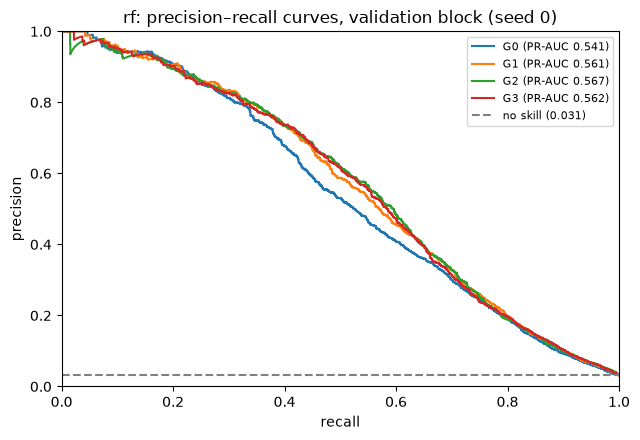

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in FEATURE_SETS:
    path = PREDS_DIR / f"{model.NAME}_{name}_val_seed0.parquet"
    if path.exists():
        p = pd.read_parquet(path)
        precision, recall, _ = precision_recall_curve(p["isFraud"], p["score"])
        ax.plot(recall, precision, label=f"{name} (PR-AUC {val.loc[name, 'pr_auc_mean']:.3f})", lw=1.5)
ax.axhline(fraud_val / n_val, ls="--", color="grey", label=f"no skill ({fraud_val / n_val:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"{model.NAME}: precision–recall curves, validation block (seed 0)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.3 What each feature group adds
Change in mean validation PR-AUC from one set to the next (same settings on every set when `TUNE_ON` is a set name).

,G0 → G1,G1 → G2,G2 → G3,G0 → G3
change in PR-AUC,0.0196,0.006,-0.0046,0.021


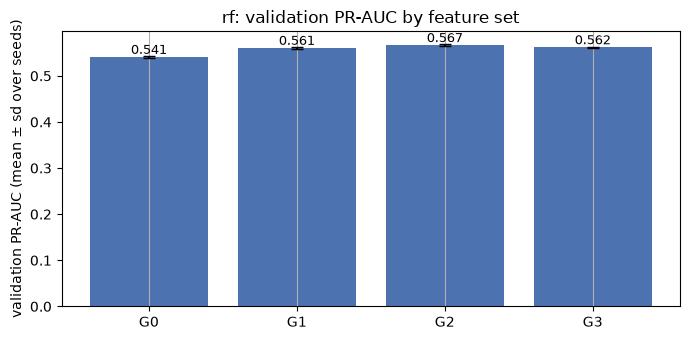

In [9]:
pr = val["pr_auc_mean"]
gains = {f"{a} → {b}": pr[b] - pr[a] for a, b in zip(FEATURE_SETS[:-1], FEATURE_SETS[1:])}
if len(FEATURE_SETS) > 2:
    gains[f"{FEATURE_SETS[0]} → {FEATURE_SETS[-1]}"] = pr[FEATURE_SETS[-1]] - pr[FEATURE_SETS[0]]
display(pd.DataFrame([gains], index=["change in PR-AUC"]).round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(val.index, val["pr_auc_mean"], yerr=val["pr_auc_std"].fillna(0), color="#4C72B0", capsize=4)
for x, y in zip(val.index, val["pr_auc_mean"]):
    ax.text(x, y, f"{y:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("validation PR-AUC (mean ± sd over seeds)")
ax.set_title(f"{model.NAME}: validation PR-AUC by feature set")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

### 5.4 Known vs unknown customers
A validation row is **known** if its `uid` appears in the training block (`src/segments.py`). PR-AUC is the mean over
the seeds, with a 95% bootstrap interval over rows (`N_BOOT` resamples). `10_model_comparison.ipynb` shows the same
split for all models side by side.

In [10]:
N_BOOT = 200
known = segments.known_uid(df["uid"].iloc[val_idx], set(df["uid"].iloc[train_idx]))
rows = []
for name in FEATURE_SETS:
    paths = [PREDS_DIR / f"{model.NAME}_{name}_val_seed{s}.parquet" for s in SEEDS]
    if not all(p.exists() for p in paths):
        print(f"{name}: validation scores not saved for every seed, skipped")
        continue
    preds = [pd.read_parquet(p) for p in paths]
    if not all((p["TransactionID"].to_numpy() == df["TransactionID"].iloc[val_idx].to_numpy()).all() for p in preds):
        raise ValueError(f"{name}: saved scores don't match the validation rows")
    t = segments.segment_pr_auc(preds[0]["isFraud"].to_numpy(), [p["score"].to_numpy() for p in preds], known,
                                n_boot=N_BOOT)
    rows.append(t.assign(feature_set=name))
if rows:
    seg = pd.concat(rows, ignore_index=True)
    display(seg.groupby("segment")[["rows", "fraud"]].first())
    seg["PR-AUC [95% interval]"] = (seg["pr_auc"].map("{:.4f}".format) + " [" + seg["low"].map("{:.3f}".format)
                                    + ", " + seg["high"].map("{:.3f}".format) + "]")
    display(seg.pivot(index="feature_set", columns="segment", values="PR-AUC [95% interval]").reindex(FEATURE_SETS))

,rows,fraud
segment,,
known,28685,640
unknown,30369,1211


segment,known,unknown
feature_set,,
G0,"0.6611 [0.627, 0.699]","0.5266 [0.498, 0.560]"
G1,"0.7119 [0.679, 0.749]","0.5237 [0.498, 0.558]"
G2,"0.7288 [0.697, 0.764]","0.5209 [0.494, 0.555]"
G3,"0.7211 [0.689, 0.756]","0.5201 [0.493, 0.554]"


### 5.5 How the settings affect performance (RQ4)

Read from the tuning runs already in the log, with no extra training: for each tuned setting and each value it
took, the mean time-CV PR-AUC of the combinations tried with that value (dot), and the best and worst of them
(bar). The star marks the chosen value. This model uses a full grid, so every value is paired with the same mix of other settings. The number of trees (boosting models) or epochs (MLP) is not
a tuned setting: early stopping picks it in every fit.

,setting,value,mean,best,worst,combinations
0,max_depth,12,0.5111,0.5185,0.4994,4
1,max_depth,24,0.5593,0.5683,0.5465,4
2,max_depth,none,0.5667,0.5847,0.5481,4
3,max_features,0.3,0.5481,0.5847,0.4994,6
4,max_features,sqrt,0.5434,0.5744,0.5089,6
5,min_samples_leaf,20,0.5415,0.5595,0.5178,6
6,min_samples_leaf,5,0.5499,0.5847,0.4994,6


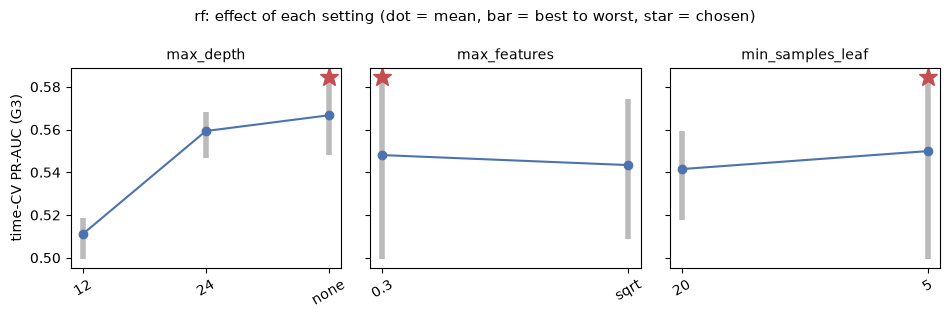

In [11]:
SENS_SET = TUNE_ON or FEATURE_SETS[-1]
sens = experiment.setting_sensitivity(model.NAME, SENS_SET, LOG_PATH)
if sens.empty:
    print("Fewer than two values tried for every setting: nothing to show.")
else:
    display(sens.round(4))
    settings_ = list(dict.fromkeys(sens["setting"]))
    n = len(settings_)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], settings_):
        part = sens[sens["setting"] == name].reset_index(drop=True)
        x = range(len(part))
        ax.vlines(x, part["worst"], part["best"], color="#BBBBBB", lw=4)
        ax.plot(x, part["mean"], "o-", color="#4C72B0")
        picked = chosen[SENS_SET].get(name)
        for i, v in enumerate(part["value"]):
            if v == picked or (picked is None and v == "none"):
                ax.plot(i, part.loc[i, "best"], "*", ms=14, color="#C44E52")
        ax.set_xticks(list(x), [str(v) for v in part["value"]], rotation=30)
        ax.set_title(name, fontsize=10)
    axes[0][0].set_ylabel(f"time-CV PR-AUC ({SENS_SET})")
    fig.suptitle(f"{model.NAME}: effect of each setting (dot = mean, bar = best to worst, star = chosen)", fontsize=11)
    fig.tight_layout()
    plt.show()

## 6. Feature importance

For the chosen settings on `IMPORTANCE_SET` (G3 by default), refit on the training block exactly as in the seed-0
validation run (cached in `results/models/`, so this runs once), then measure:

- **Permutation importance:** how much validation PR-AUC drops when one input column is shuffled (on
  `IMPORTANCE_ROWS` validation rows). It means the same thing for every model, so it can be compared across notebooks.
- **Built-in importance:** mean decrease in Gini impurity (scikit-learn's `feature_importances_`); it tends to favour columns with many distinct values.

Correlated columns share credit: shuffling one leaves its near-copy in place, so a small drop does not prove a column
is useless. Importances describe what this model relies on, not causes of fraud. The table is also saved to
`results/importance/` for `10_model_comparison.ipynb`.

In [12]:
cols = sets[IMPORTANCE_SET]
fitted, pipe = experiment.fit_final(model, lambda: make_pipeline(cols), df, train_idx, chosen[IMPORTANCE_SET],
                                    IMPORTANCE_SET, seed=0, cache_dir=MODELS_DIR)
X_val = pipe.transform(df.iloc[val_idx])
y_val = df["isFraud"].iloc[val_idx].to_numpy()
group_of = importance.feature_groups(spec)

perm = importance.permutation(fitted, X_val, y_val, cols, n_rows=IMPORTANCE_ROWS, seed=0)
built_in = importance.intrinsic(model, fitted, list(X_val.columns), cols)
imp = perm[["pr_auc_drop"]].assign(group=[group_of.get(c, "?") for c in perm.index])
if built_in is not None:
    imp["built_in"] = built_in
    imp["built_in_share"] = built_in / built_in.sum()
imp = imp.sort_values("pr_auc_drop", ascending=False)
print(f"PR-AUC on the {min(IMPORTANCE_ROWS, len(val_idx)):,} rows used: {perm['base_pr_auc'].iloc[0]:.4f} "
      f"(built-in importance: {model.IMPORTANCE or 'none'})")
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)
imp.assign(model=model.NAME, feature_set=IMPORTANCE_SET).to_csv(IMPORTANCE_DIR / f"{model.NAME}_{IMPORTANCE_SET}.csv")
display(imp.head(20).round(4))

PR-AUC on the 20,000 rows used: 0.5520 (built-in importance: mean impurity decrease)


,pr_auc_drop,group,built_in,built_in_share
feature,,,,
C1,0.1152,G0_raw,0.0248,0.0248
C11,0.0330,G0_raw,0.0143,0.0143
C2,0.0212,G0_raw,0.0118,0.0118
fe_freq_card1,0.0204,G2_card_device_history,0.0267,0.0267
C14,0.0177,G0_raw,0.0302,0.0302
fe_D1n,0.0172,G1_row_level,0.0259,0.0259
card1,0.0163,G0_raw,0.0214,0.0214
V283,0.0147,G0_raw,0.0231,0.0231
C13,0.0144,G0_raw,0.0292,0.0292


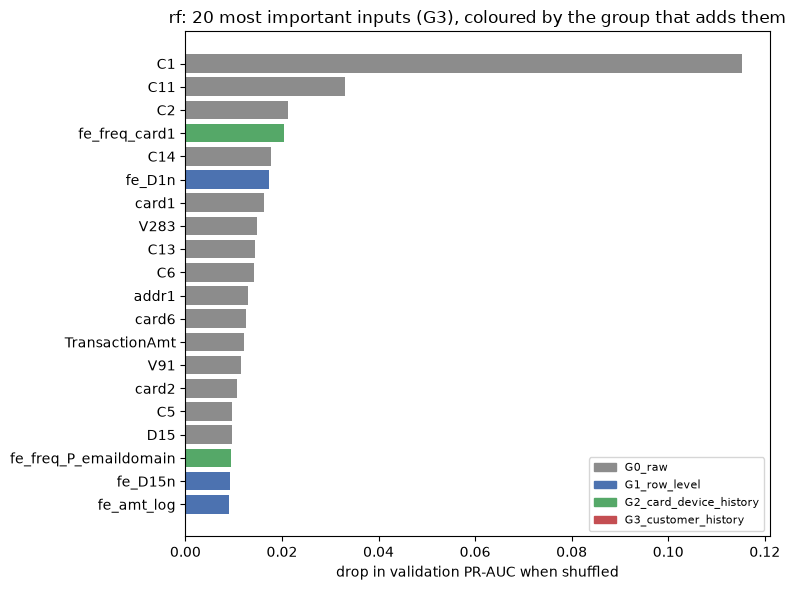

Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):


,sum,count
group,,
G0_raw,0.4051,197
G1_row_level,0.0668,27
G2_card_device_history,0.0476,10
G3_customer_history,0.0107,18


In [13]:
top = imp.head(20).iloc[::-1]
colors = {"G0_raw": "#8C8C8C", "G1_row_level": "#4C72B0", "G2_card_device_history": "#55A868",
          "G3_customer_history": "#C44E52"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pr_auc_drop"], color=[colors.get(g, "#999999") for g in top["group"]])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, list(colors), fontsize=8, loc="lower right")
ax.set_xlabel("drop in validation PR-AUC when shuffled")
ax.set_title(f"{model.NAME}: 20 most important inputs ({IMPORTANCE_SET}), coloured by the group that adds them")
fig.tight_layout()
plt.show()

print("Total PR-AUC drop by feature group (sum over its columns; groups overlap in what they capture):")
display(imp.groupby("group")["pr_auc_drop"].agg(["sum", "count"]).sort_values("sum", ascending=False).round(4))

## 7. Findings

Write this after running, quoting only numbers from the tables above:

- Which feature set scores best, and how much each step adds (G0 → G1 → G2 → G3; table 5.3).
- How known and unknown customers compare, and whether history features (G2, G3) help mainly known ones (5.4).
- Whether the chosen settings sit at the edge of the grid (a sign the grid should be widened).
- Anything unusual, such as a large spread between seeds.
- Which settings matter most (5.5): where the mean moves a lot across values, and where it barely moves.
- Which inputs matter most (section 6), whether the engineered features (G1–G3) are among them, and whether that fits
  the EDA (for example the customer-history features mattering mainly for known customers).